In [3]:
from clingo import Control, Model
from clingo.ast import parse_string, ProgramBuilder
from clingodl import ClingoDLTheory
import time
time_limit=15
ctl = Control(["--opt-mode=opt", "--opt-strategy=usc"])
thy = ClingoDLTheory()
thy.register(ctl)

prg = """
% Graph definition
node(a; b; c; d).
edge(a,b). edge(b,c). edge(c,d). edge(d,a). edge(a,c).

% Each node can be in the cover or not
{ cover(X) } :- node(X).

% Every edge must be covered by at least one endpoint
:- edge(X,Y), not cover(X), not cover(Y).

% Assign weights (costs) to nodes
weight(a, 2).
weight(b, 1).
weight(c, 3).
weight(d, 1).

% Minimize the total weight of selected nodes
#minimize { W,X : cover(X), weight(X,W) }.
"""
with ProgramBuilder(ctl) as bld:
    parse_string(prg, lambda ast: thy.rewrite_ast(ast, bld.add))
try:
    print('Start Grounding...')
    ctl.ground([('base', [])])
    thy.prepare(ctl)
    print('Done grounding!')
    print('Start Solving...')
    with ctl.solve(yield_=True, on_model=thy.on_model, async_=True) as hnd:
        start_time = time.time()
        time_limit = time_limit
        while True:
            hnd.resume()
            flag = hnd.wait(time_limit)
            print(flag, time_limit)
            time_limit = time_limit - (time.time() - start_time)
            if time_limit <= 0 or not flag:
                print('Stop solving')
                hnd.cancel()
                break
            else: print(f"{time_limit - time_limit}, {hnd.get()}")

            print(hnd.model())
            # print(LINE)
            
        hnd.cancel()
except KeyboardInterrupt:
    print("\nSolving interrupted by keyboard...")
finally:
    pass


Start Grounding...
Done grounding!
Start Solving...
True 15
0.0, SAT
node(a) node(b) node(c) node(d) cover(a) cover(b) cover(d) edge(a,b) edge(b,c) edge(c,d) edge(d,a) edge(a,c) weight(a,2) weight(b,1) weight(c,3) weight(d,1)
True 14.999912977218628
0.0, SAT
None
True 14.999632835388184
0.0, SAT
None
True 14.99933385848999
0.0, SAT
None
True 14.999018669128418
0.0, SAT
None
True 14.998687505722046
0.0, SAT
None
True 14.99834132194519
0.0, SAT
None
True 14.99798035621643
0.0, SAT
None
True 14.997604131698608
0.0, SAT
None
True 14.997212886810303
0.0, SAT
None
True 14.996805667877197
0.0, SAT
None
True 14.996379613876343
0.0, SAT
None
True 14.995938539505005
0.0, SAT
None
True 14.995482444763184
0.0, SAT
None
True 14.995011329650879
0.0, SAT
None
True 14.994523286819458
0.0, SAT
None
True 14.994017124176025
0.0, SAT
None
True 14.993496179580688
0.0, SAT
None
True 14.992958068847656
0.0, SAT
None
True 14.99240493774414
0.0, SAT
None
True 14.991837739944458
0.0, SAT
None
True 14.9912536144

In [12]:
# Read greedy.csv and exp0.csv
with open('greedy.csv', 'r') as file:
    greedy_lines = file.read().strip().split('\n')

with open('exp0.csv', 'r') as file:
    exp_lines = file.read().strip().split('\n')

result_lines = []
for i, (exp_line, greedy_line) in enumerate(zip(exp_lines, greedy_lines)):
    exp_cols = exp_line.split(',')
    greedy_cols = greedy_line.split(',')

    # Swap column 2 and 3 (index 1 and 2)
    exp_cols[0], exp_cols[1] = exp_cols[1], exp_cols[0]

    # Replace columns 4,5,6 (index 3,4,5) of exp with columns 1,2,3 (index 0,1,2) of greedy
    exp_cols[3:6] = greedy_cols[0:3]

    # Format to LaTeX table row
    row = f"{i+1}&" + '&'.join(exp_cols) + r'\\'
    result_lines.append(row)

result = '\n'.join(result_lines)
print(result)

# Write to file
with open('table.txt', 'w') as out_file:
    out_file.write(result)

1&10&18&7&97&&<1&TO&TO&60&65&1491&14&90&2220&2&97&2330&2&TO&TO&60&98&2350&3\\
2&10&16&8&98&&<1&14&321&29&69&1564&13&94&2273&2&99&2356&2&TO&TO&60&99&2351&2\\
3&10&14&9&96&&<1&15&330&19&63&1473&9&91&2241&2&98&2347&2&TO&TO&60&99&2353&2\\
4&10&13&10&93&&<1&20&423&16&69&1579&14&TO&TO&60&99&2357&2&TO&TO&60&99&2350&4\\
5&10&12&11&89&&<1&TO&TO&60&65&1442&14&TO&TO&60&97&2328&2&TO&TO&60&TO&TO&60\\
6&10&11&12&78&&<1&TO&TO&60&60&1245&13&TO&TO&60&TO&TO&60&TO&TO&60&TO&TO&60\\
7&20&30&7&90&&<1&TO&TO&60&60&2702&29&80&4235&3&94&4621&3&TO&TO&60&94&4617&8\\
8&20&27&8&94&&<1&TO&TO&60&62&2896&25&84&4317&3&95&4621&3&TO&TO&60&97&4681&7\\
9&20&24&9&96&&<1&TO&TO&60&60&2655&19&82&4272&3&93&4580&3&TO&TO&60&97&4686&13\\
10&20&21&10&81&&<1&TO&TO&60&58&2620&21&TO&TO&60&92&4552&3&TO&TO&60&94&4606&12\\
11&20&20&11&78&&<1&TO&TO&60&62&2669&30&TO&TO&60&90&4494&4&TO&TO&60&TO&TO&60\\
12&20&18&12&68&&<1&TO&TO&60&54&2245&29&TO&TO&60&TO&TO&60&TO&TO&60&TO&TO&60\\
13&50&78&7&TO&TO&60&TO&TO&60&TO&TO&60&83&10736&7&93&11462&7&TO&

In [6]:
import clingo
ctl = clingo.Control()
ctl.add("base", [], "a. #external b(1..3).")
ctl.ground([("base", [])])
ctl.assign_external(clingo.Function("b", [clingo.Number(2)]), True)
ctl.solve(on_model=lambda m: print("Answer: {}".format(m)))

ctl.release_external(clingo.Function("b"))
ctl.solve(on_model=lambda m: print("Answer: {}".format(m)))

Answer: b(2) a
Answer: b(2) a


SolveResult(1)

In [2]:
import pandas as pd
import numpy as np
import re
from collections import defaultdict
import sys
import os
import math
# import matplotlib.pyplot as plt
# import pyomo.environ as pyenv
import json
import pprint
velocity = 100 # mph
e_dischg = 4 # kWh/mile
e_max = 100 # kWh
g_i=250 # kW
city_names = ["lgr", "jfk", "rep", "lima", "dtm", "ttb", "nli"]

dist = np.array([
    [ 0., 10.68, 24.32, 40.51,  8.876, 11.08, 16.6],
    [10.68,  0.,  20.15, 37.19, 12.82,  20.73, 20.81],
    [24.32,  20.15,  0., 17.05, 31.33,  34.96,  39.74],
    [40.51, 37.19, 17.05,  0., 48.12,  50.47,  56.5],
    [ 8.876, 12.82, 31.33, 48.12,  0., 10.63, 8.407],
    [11.08,  20.73,  34.96,  50.47, 10.63,  0.,  12.26],
    [16.6, 20.81,  39.74,  56.5, 8.407,  12.26,  0.]
])
def EstimateMinAgents(horizon, b_init, demand_cust, aircraft_capacity, random_cust, nb_vertiports=7):
    """
    b_init in charging minute
    """
    if random_cust:
        minimum_flights_per_edge = [math.ceil(demand/aircraft_capacity) for demand in demand_cust]
    else:
        minimum_flights_per_edge = math.ceil(demand_cust/aircraft_capacity)
    require_operation_time = dist*(60/velocity + e_dischg*60/g_i)
    require_operation_time_serve_all_cust = np.array(minimum_flights_per_edge) * require_operation_time.flatten()
    min_number_agents = np.ceil(sum(require_operation_time_serve_all_cust)/(horizon+b_init)).astype(int)
    if random_cust:
        min_number_segments = (np.ceil(np.sum(minimum_flights_per_edge)/min_number_agents)).astype(int)
    else:
        min_number_segments = (np.ceil(minimum_flights_per_edge*(nb_vertiports*(nb_vertiports-1))/min_number_agents)).astype(int)
    return min_number_agents, min_number_segments

EstimateMinAgents(180, 0, 30, 4, False, 7)
# from instances.gen_instance import InitLoc, GenRq
# InitLoc(74, limit_nAgents_each_vertiport=74, out_file='instances/init_a74_NY_1.lp')
# GenRq(cust=30, out_file='instances/rq_30_NY_1.lp')

(np.int64(74), np.int64(5))

In [1]:
import pandas as pd
import sys
# List of files to join
# files = [
#     'exp0_Greedy.csv', 
#     # 'exp0_O1.csv', 
#     'exp0_O2.csv',
#     # 'exp0_H1.csv', 
#     'exp0_H2.csv', 
#     # 'exp0_O1H2.csv', 
#     'exp0_O2H2.csv'
# ]
files = [
     
    'exp0_O1.csv', 
    
    'exp0_H1.csv', 
    
    'exp0_O1H2.csv' 
    
]
# Read all CSVs into dataframes
dfs = [pd.read_csv(f) for f in files]

# # if any value in dfs is a string of integer, transfer it to integer
# for df in dfs:
#     for col in df.columns:
#         if df[col].dtype == object:
#             # Try to convert to numeric, but keep non-convertible as is (e.g., 'TO', 'AVG')
#             df[col] = pd.to_numeric(df[col], errors='ignore')
# Concatenate along columns (axis=1)
joined_df = pd.concat(dfs, axis=1)


# Save to exp0.csv
# Drop duplicate columns except for the first occurrence
joined_df = joined_df.loc[:,~joined_df.columns.duplicated()]
# joined_df.to_csv('exp0.csv', index=False)
# append the row index as first column
joined_df.insert(0, 'row_idx', range(1, len(joined_df) + 1))
# remove column nb_segment
joined_df = joined_df.drop(columns=['nb_segment'])

joined_df.to_csv('exp0_0.csv', index=False)
# except first row (columns name); for every 5 rows; add a row next that are average of that 5 rows 
new_rows = []
n = 5
for i in range(0, len(joined_df), n):
    chunk = joined_df.iloc[i:i+n]
    new_rows.extend(chunk.values.tolist())
    avg_row = []
    for j, col in enumerate(chunk.columns):
        if j == 0:
            avg_row.append('AVG')
            continue
        # Try to convert the column to numeric, keeping non-convertible as is
        chunk[col] = pd.to_numeric(chunk[col], errors='ignore')
        # Only take mean of numeric cells, ignore non-numeric (e.g., 'TO')
        numeric_vals = pd.to_numeric(chunk[col], errors='coerce')
        if numeric_vals.notna().any():
            avg_row.append(numeric_vals.mean())
        else:
            avg_row.append('TO')
    new_rows.append(avg_row)
    
joined_df = pd.DataFrame(new_rows, columns=joined_df.columns)
joined_df.to_csv('exp0.csv', index=False)

# # replace ',' with '&'
# # add '&' at the beginning of row 
# # print to txt file; ignore column name

with open('exp0.csv', 'r') as f:
    lines = f.readlines()

with open('exp0_latex.txt', 'w') as out:
    for line in lines[1:]:  # skip header
        line = line.strip()
        # Try to convert each value to int if possible, else keep as is
        items = line.split(',')
        new_items = []
        for item in items:
            try:
                # Only convert if it's a number and not 'TO' or 'AVG'
                if item not in ['TO', 'AVG']:
                    fval = float(item)
                    ival = int(fval)
                    # If float is integer-valued, use int
                    if fval == ival:
                        new_items.append(str(ival))
                    else:
                        new_items.append(str(fval))
                else:
                    new_items.append(item)
            except ValueError:
                new_items.append(item)
        line = '&'.join(new_items) + r' \\'
        out.write(line + '\n')

/var/folders/ym/9c00hgdn67x8lqgkpg02zc7w0000gn/T/ipykernel_81740/1073021460.py:57: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  chunk[col] = pd.to_numeric(chunk[col], errors='ignore')
/var/folders/ym/9c00hgdn67x8lqgkpg02zc7w0000gn/T/ipykernel_81740/1073021460.py:57: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  chunk[col] = pd.to_numeric(chunk[col], errors='ignore')


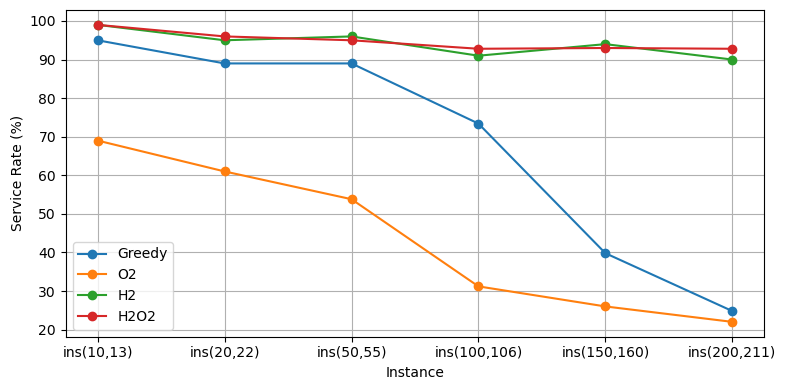

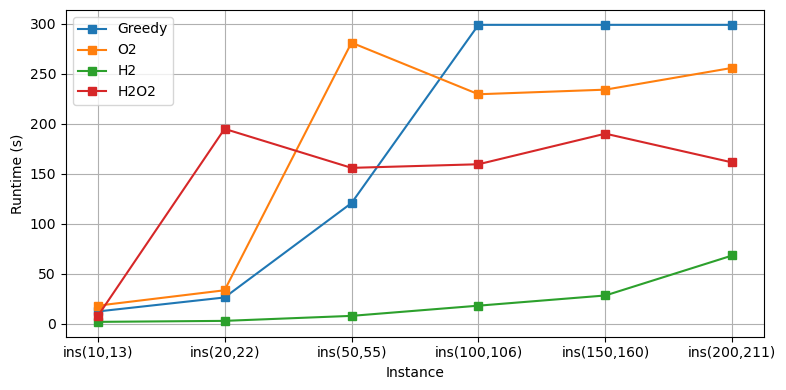

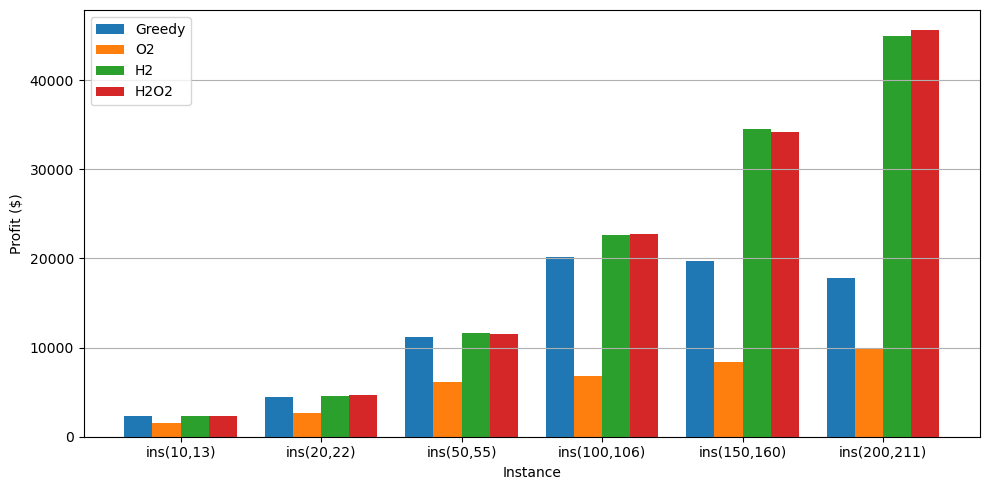

In [6]:
# plots_generation.py

import matplotlib.pyplot as plt
import numpy as np
from cycler import cycler

# Define color mapping for each config with high-contrast, colorblind-friendly tones
config_colors = {
    "Greedy": "#1f77b4",   # blue
    "O2": "#ff7f0e",       # orange
    "H2": "#2ca02c",       # green
    "H2O2": "#d62728"      # red
}

def plot_service_rate(demands, service_rate, configs, svg_filename="service_rate.svg"):
    plt.figure(figsize=(8, 4))
    x_labels = [f"ins({d[0]},{d[1]})" for d in demands]
    x = np.arange(len(demands))
    for cfg in configs:
        plt.plot(x, service_rate[cfg], marker='o', label=cfg, color=config_colors[cfg])
    plt.xticks(x, x_labels)
    plt.xlabel("Instance")
    plt.ylabel("Service Rate (%)")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.savefig(svg_filename, format="svg")
    plt.show()
    plt.close()

def plot_runtime(demands, runtime, configs, svg_filename="runtime.svg"):
    plt.figure(figsize=(8, 4))
    x_labels = [f"ins({d[0]},{d[1]})" for d in demands]
    x = np.arange(len(demands))
    for cfg in configs:
        plt.plot(x, runtime[cfg], marker='s', label=cfg, color=config_colors[cfg])
    plt.xticks(x, x_labels)
    plt.xlabel("Instance")
    plt.ylabel("Runtime (s)")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.savefig(svg_filename, format="svg")
    plt.show()
    plt.close()

def plot_profit(demands, profit, configs, svg_filename="profit.svg"):
    x_labels = [f"ins({d[0]},{d[1]})" for d in demands]
    x = np.arange(len(demands))
    bar_width = 0.2
    plt.figure(figsize=(10, 5))
    for i, cfg in enumerate(configs):
        plt.bar(x + (i-1.5)*bar_width, profit[cfg], width=bar_width, label=cfg, color=config_colors[cfg])
    plt.xticks(x, x_labels)
    plt.xlabel("Instance")
    plt.ylabel("Profit ($)")
    plt.legend()
    plt.grid(axis='y')
    plt.tight_layout()
    plt.savefig(svg_filename, format="svg")
    plt.show()
    plt.close()

def main():
    # Demand levels and performance data
    demands = [(10,13), (20,22), (50,55), (100,106), (150,160), (200,211)]
    configs = ["Greedy", "O2", "H2", "H2O2"]

    service_rate = {
        "Greedy": [95, 89, 89, 73.4, 39.8, 24.8],
        "O2":     [69, 61, 53.8, 31.2, 26,   22],
        "H2":     [99, 95, 96,   91,   94,   90],
        "H2O2":   [99, 96, 95,   92.8, 93,   92.8]
    }

    runtime = {
        "Greedy": [12.4, 26.4, 120.8, 299,   299,   299],
        "O2":     [18.2, 33.6, 281.2, 229.6, 234.2, 256],
        "H2":     [2,     3,     8,    18.2,  28.4,  68.4],
        "H2O2":   [7.6,  195,   156,  159.6, 190.2, 161.4]
    }

    profit = {
        "Greedy": [2305, 4464, 11147, 20122.8, 19664,   17855.4],
        "O2":     [1579, 2692, 6168,  6772,    8341.2,  9803.4],
        "H2":     [2356, 4613, 11598, 22575,   34499,   44931],
        "H2O2":   [2350, 4653, 11517.6,22779.2, 34234.2, 45587.8]
    }

    plot_service_rate(demands, service_rate, configs)
    plot_runtime(demands, runtime, configs)
    plot_profit(demands, profit, configs)

if __name__ == "__main__":
    main()
